# gpxil quick start

Turn a chromosome and one person's genotypes into a gpxil genome pixel image,
look at it, analyse it as an image, and print it.

Data (all public): GRCh38 chromosome 21 from Ensembl, and the Genome in a Bottle
HG002 small-variant benchmark (v5.0q). Runs in Google Colab or any Python 3.10+.

In [1]:
import importlib.util

if importlib.util.find_spec("gpxiltools") is None:
    %pip install -q git+https://github.com/comparativechrono/Gpxil-tools scikit-image pysam

## 1. Download the data

In [2]:
import os
import urllib.request

os.makedirs("data", exist_ok=True)
ENSEMBL = "https://ftp.ensembl.org/pub/release-116/fasta/homo_sapiens/dna"
GIAB = "https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/giab/release/AshkenazimTrio/HG002_NA24385_son/v5.0q"
files = {
    "chr21.fa.gz": f"{ENSEMBL}/Homo_sapiens.GRCh38.dna_sm.chromosome.21.fa.gz",
    "HG002.vcf.gz": f"{GIAB}/HG002_GRCh38_v5.0q_smvar.vcf.gz",
    "HG002.vcf.gz.tbi": f"{GIAB}/HG002_GRCh38_v5.0q_smvar.vcf.gz.tbi",
    "HG002.benchmark.bed": f"{GIAB}/HG002_GRCh38_v5.0q_smvar.benchmark.bed",
}
for name, url in files.items():
    path = os.path.join("data", name)
    if not os.path.exists(path):
        print("downloading", name)
        urllib.request.urlretrieve(url, path)
print(sorted(os.listdir("data")))

['HG002.benchmark.bed', 'HG002.vcf.gz', 'HG002.vcf.gz.tbi', 'HG002_chr21.vcf', 'chr21.fa.gz']


Keep only chromosome 21 of the VCF (the index makes this quick).

In [3]:
import pysam

pysam.set_verbosity(0)  # the GIAB index is older than its VCF; harmless
vcf = pysam.TabixFile("data/HG002.vcf.gz")
with open("data/HG002_chr21.vcf", "w") as out:
    out.writelines(h + "\n" for h in vcf.header)
    out.writelines(r + "\n" for r in vcf.fetch("chr21"))

## 2. Encode

The FASTA calls the chromosome `21`, the VCF `chr21`; gpxiltools matches them.
`--callable` marks everything outside the benchmark regions as unknown rather
than reference.

In [4]:
!gpxil encode data/chr21.fa.gz -v data/HG002_chr21.vcf --callable data/HG002.benchmark.bed --ucsc-names --reference-name GRCh38 -o HG002_chr21.gpxil.tif
!gpxil info HG002_chr21.gpxil.tif
!gpxil validate HG002_chr21.gpxil.tif

splitting HG002_chr21.vcf by contig for sample HG002 ...


  chr21: 46,709,983 bp, 113,870 records  [12s]
wrote HG002_chr21.gpxil.tif: 1 contigs, 46,709,983 bases, 11.9 MB in 12.3s


HG002_chr21.gpxil.tif: gpxil 0.1, written by gpxiltools 0.2.0, 2026-10-27T02:07:46+00:00
reference: GRCh38 (chr21.fa.gz)
sample: HG002 from HG002_chr21.vcf, callable regions HG002.benchmark.bed
layout: raster, width 8192; palette classic
contig                  length  planes                     records  sidecar
chr21               46,709,983  ref,gt,flags               113,870   11,257


HG002_chr21.gpxil.tif: valid (1 contigs checked, 0 errors, 0 warnings)


The result is an ordinary TIFF: open it in any image viewer and the first page
is chromosome 21, one pixel per base. In Python every plane is an array.

In [5]:
import numpy as np
from gpxiltools import GpxilFile, codes

g = GpxilFile("HG002_chr21.gpxil.tif")
chr21 = g["chr21"]
print(chr21, chr21.width, "bases per row,", chr21.rows, "rows")
start = 42_863_616                               # 0-based offset = VCF POS - 1
ref = chr21.read("ref", start, start + 1024)      # one uint8 per base
gt = chr21.read("gt", start, start + 1024)        # haplotype 1 in the high nibble, 2 in the low
print(chr21.sequence(start, start + 64))
for i in np.flatnonzero(gt)[:12]:
    print(f"chr21:{start + i + 1:,}  ref {codes.IUPAC[ref[i] & 15]}  gt 0x{gt[i]:02x}  {codes.describe_gt_byte(int(gt[i]))}")

<Contig chr21 length=46709983 planes=['ref', 'gt', 'flags']> 8192 bases per row, 5702 rows
CCCCATTAGCTTCCAGGAGCAGCGCAGGGTCCTCGACAGCCTGGCAGGCCACGTGGGCGGTGGC
chr21:42,863,675  ref G  gt 0x10  A|REF
chr21:42,863,828  ref C  gt 0x88  T|T
chr21:42,863,873  ref G  gt 0x11  A|A
chr21:42,863,889  ref A  gt 0x44  G|G
chr21:42,863,897  ref G  gt 0x10  A|REF
chr21:42,863,902  ref T  gt 0x22  C|C
chr21:42,863,903  ref G  gt 0x11  A|A
chr21:42,863,905  ref G  gt 0x01  REF|A
chr21:42,863,908  ref C  gt 0x10  A|REF
chr21:42,863,909  ref A  gt 0x20  C|REF
chr21:42,863,911  ref T  gt 0x22  C|C
chr21:42,863,927  ref A  gt 0xd0  DEL|REF


## 3. Look at it

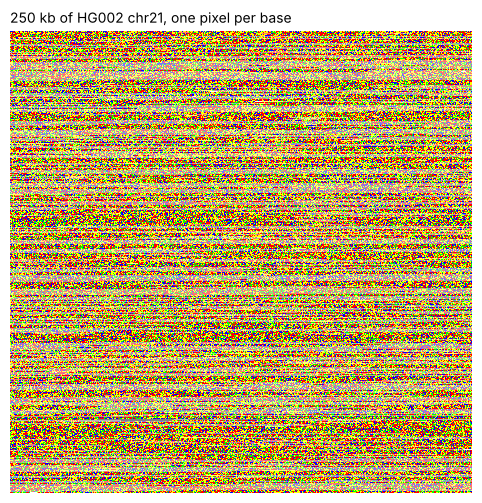

In [6]:
import matplotlib.pyplot as plt
from gpxiltools.render import render

def show(r, title, scale=1, size=(6, 6)):
    plt.figure(figsize=size)
    plt.imshow(r.scaled(scale).to_rgb(), interpolation="nearest")
    plt.title(title, loc="left", fontsize=10)
    plt.axis("off")
    plt.show()

show(render(chr21, start=30_000_000, end=30_250_000, bases_per_row=500), "250 kb of HG002 chr21, one pixel per base")

Zoom in on 1 kb. In **genotype** mode a heterozygous site is drawn in
the mix of its two alleles' colours; **haplotypes** mode draws the two inherited
copies as separate rows; **variants** mode highlights where this genome differs
from the reference.

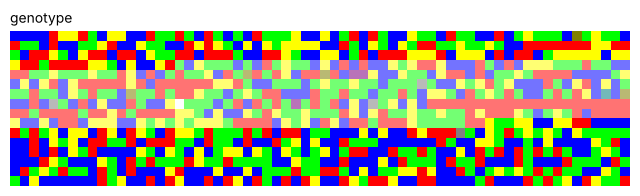

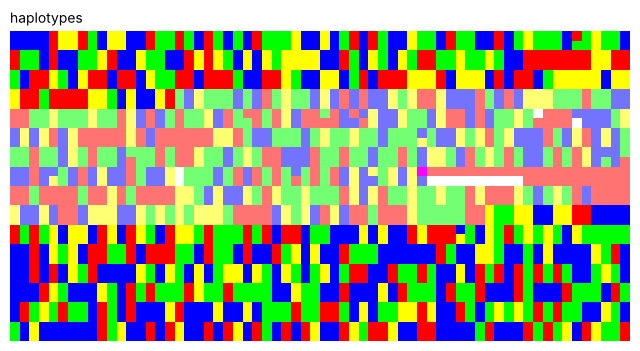

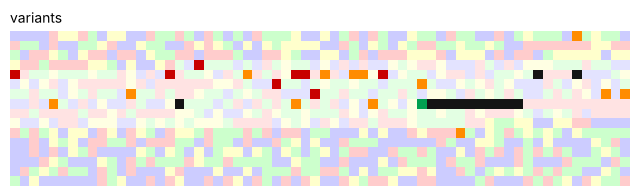

In [7]:
start, bpr, rows = 42_863_616, 64, 16
for mode in ("genotype", "haplotypes", "variants"):
    r = render(chr21, mode=mode, start=start, end=start + bpr * rows, bases_per_row=bpr, mark_insertions=True)
    show(r, mode, scale=6, size=(8, 4 if mode != "haplotypes" else 7))

The same region in the four built-in palettes; each is defined in sRGB for screens and CMYK for print.

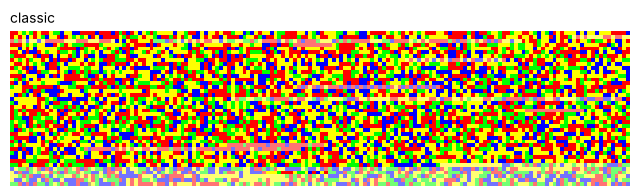

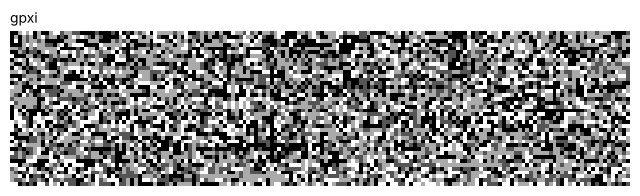

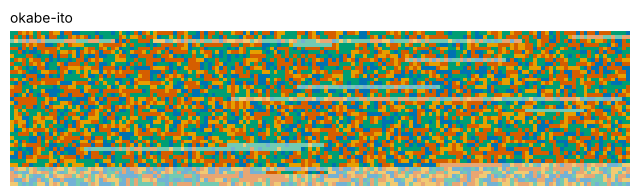

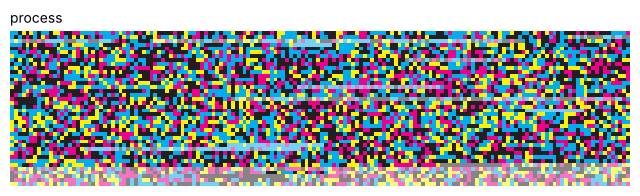

In [8]:
from gpxiltools.palettes import PALETTES
for name in PALETTES:
    show(render(chr21, palette=name, start=30_100_000, end=30_100_000 + 160 * 40, bases_per_row=160), name, scale=3, size=(8, 2.5))

## 4. Analyse it as an image

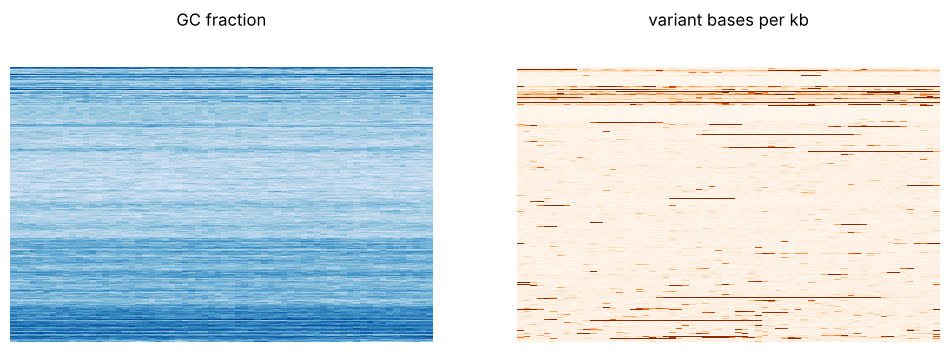

In [9]:
from skimage.measure import block_reduce

whole_ref = chr21.image("ref")      # (rows, 8192)
whole_gt = chr21.image("gt")
base = whole_ref & 0x0F
acgt = np.isin(base, codes.HAP_SUB_CODES)
gc = np.isin(base, (codes.BASE_C, codes.BASE_G))
variant = (whole_gt != 0) & (whole_gt != codes.GT_UNKNOWN)
blk = (16, 128)
n = block_reduce(acgt, blk, np.sum)
gc_map = np.where(n > 0, block_reduce(gc, blk, np.sum) / np.maximum(n, 1), np.nan)
var_map = np.where(n > 0, block_reduce(variant, blk, np.sum) / np.maximum(n, 1) * 1000, np.nan)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(gc_map, cmap="Blues", interpolation="nearest", aspect="auto")
ax[0].set_title("GC fraction")
ax[1].imshow(var_map, cmap="Oranges", interpolation="nearest", aspect="auto", vmax=np.nanpercentile(var_map, 98))
ax[1].set_title("variant bases per kb")
for a in ax:
    a.axis("off")
plt.show()

A Hilbert-curve view keeps neighbouring bases together in 2-D: GC-rich and N-rich regions become blocks.

wrote chr21-hilbert.png: 8192 x 8192 px, chr21:1-46,709,983


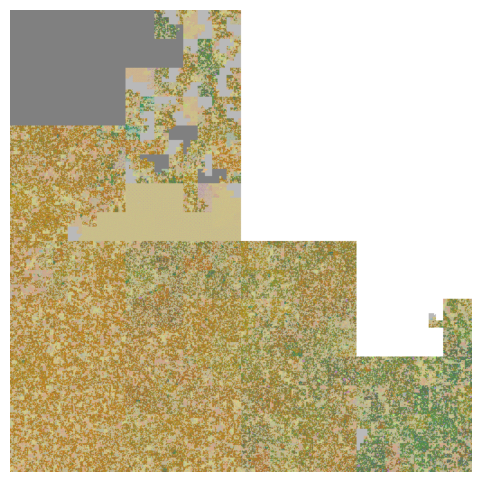

In [10]:
!gpxil render HG002_chr21.gpxil.tif chr21 -o chr21-hilbert.png --layout hilbert --mode reference
from PIL import Image
Image.MAX_IMAGE_PIXELS = None
plt.figure(figsize=(6, 6))
plt.imshow(Image.open("chr21-hilbert.png").convert("RGB").resize((1024, 1024), Image.BOX))
plt.axis("off")
plt.show()

## 5. Print it

A book with one printed dot per base: A4 at 300 dpi holds 6.3 million bases a
page, so chromosome 21 is 8 pages (the whole genome is about 500). The colours
are device CMYK; `--rgb` makes a screen version.

In [11]:
!gpxil book HG002_chr21.gpxil.tif -o HG002_chr21_book.pdf --contigs chr21
!gpxil render HG002_chr21.gpxil.tif chr21:30,000,001-30,250,000 -o region-cmyk.tif --width 500 --cmyk --dpi 300

cover


wrote HG002_chr21_book.pdf: 11 pages, 6,314,220 bases per full page


wrote region-cmyk.tif: 500 x 500 px, chr21:30,000,001-30,250,000


## 6. Back to sequences and VCF

In [12]:
!gpxil fasta HG002_chr21.gpxil.tif --which 1 --region chr21:42,863,617-42,864,640 -o hap1.fa
!gpxil fasta HG002_chr21.gpxil.tif --which 2 --region chr21:42,863,617-42,864,640 -o hap2.fa
!gpxil vcf HG002_chr21.gpxil.tif -o HG002_chr21.from-gpxil.vcf
print(open("hap1.fa").read()[:300])

wrote 149,977 records


>chr21:42863617-42864640_hap1
CCCCATTAGCTTCCAGGAGCAGCGCAGGGTCCTCGACAGCCTGGCAGGCCACGTGGGCAG
TGGCAGGCACCGGTACCTGGCCATATGCTCTGTTTTCCAGCTGCTGAAGGTGGTGCCAAA
AAAATTAAGCAATGCTAACAACTGGAACAAAGCCAATGCCTTCGACAAATTTACTTTCAC
AACGTTTTTCTTTAAGAAAATTGCTCCTAgctgggcgcagtggctcacacctgtaatccc
agcactttgggaggccaaggtgggtg


A gpxil file of a person, and every faithful picture or print of it, is that
person's genome. HG002 is a consented, public reference genome; treat anyone
else's with the care you would give their VCF.